**Exploratory Data Analysis**

This analysis will be exploring the relationships between GDP per capita, Life expectancy at rate, and Unemployment rate.

In addition, it looks at understanding the variables in the dataset, and the basic statitics of the numerical values


In [3]:
# Necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# Create function that cleans the dataset
def clean(filepath):
    data = pd.read_csv(filepath)

    # Rename first columns
    new_columns = {"Country Name": "country_name", "Series Name": "series_name"}
    data.rename(columns=new_columns, inplace=True)

    # Rename year columns
    data.rename(
        columns={f"{year} [YR{year}]": str(year) for year in range(2000, 2025)},
        inplace=True,
    )

    # Remove Country Code and Series Code columns
    data.drop(columns=["Country Code", "Series Code"], inplace=True)

    # Remove the bottom 5 rows
    data = data.iloc[:-5].copy()

    # Replace ".." with missing values
    year_columns = [str(year) for year in range(2000, 2025)]
    data[year_columns] = data[year_columns].replace("..", float("nan"))

    # Convert year columns to float
    data[year_columns] = data[year_columns].astype(float)

    return data

In [5]:
# Loading necessary dataset
df = clean("data/combined_dataset.csv")
df.head()

,country_name,series_name,2000,2001,2002,2003,2004,2005,2006,2007,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Afghanistan,GDP per capita (current US$),174.930991,138.706822,178.954088,198.871116,221.763654,254.184249,274.218554,376.223152,...,565.569730,522.082216,525.469771,491.337221,496.602504,510.787063,356.496214,357.261153,413.757895,416.871146
1,Afghanistan,"Life expectancy at birth, total (years)",55.005000,55.511000,56.225000,57.171000,57.810000,58.247000,58.553000,58.956000,...,62.270000,62.646000,62.406000,62.443000,62.941000,61.454000,60.417000,65.617000,66.035000,66.289000
2,Afghanistan,"Unemployment, total (% of total labor force) (...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,11.184000,NaN,NaN,11.710000,5.679000,NaN,NaN,NaN
3,Albania,GDP per capita (current US$),1160.420471,1326.416524,1479.838846,1908.699007,2446.909499,2741.721365,3057.772570,3743.055299,...,4199.539129,4457.634122,5006.360130,5897.654526,6069.439031,6027.913507,7242.455131,7756.961887,9740.702341,11374.008578
4,Albania,"Life expectancy at birth, total (years)",74.826000,75.083000,75.299000,75.557000,75.951000,76.427000,76.994000,77.691000,...,78.358000,78.643000,78.900000,79.238000,79.467000,77.824000,76.844000,78.769000,79.602000,79.776000


In [6]:
# Taking the mean of gdp, unemployment rate, and life expectancy of each country from 2000-2024
years = [str(year) for year in range(2000, 2025)]

# GDP per capita
gdp_data = df[df["series_name"] == "GDP per capita (current US$)"]

mean_gdp = (
    gdp_data.groupby("country_name")[years]
    .mean()
    .mean(axis=1)
    .reset_index(name="GdpMean")
)

# Unemployment rate
unemployment_data = df[
    df["series_name"]
    == "Unemployment, total (% of total labor force) (national estimate)"
]

mean_unemployment = (
    unemployment_data.groupby("country_name")[years]
    .mean()
    .mean(axis=1)
    .reset_index(name="UnemploymentMean")
)

# Life expectancy
lifexp_data = df[df["series_name"] == "Life expectancy at birth, total (years)"]

mean_lifexp = (
    lifexp_data.groupby("country_name")[years]
    .mean()
    .mean(axis=1)
    .reset_index(name="LifeExpectancyMean")
)

# Merge datasets
data = mean_gdp.merge(mean_unemployment, on="country_name", how="outer").merge(
    mean_lifexp, on="country_name", how="outer"
)

data.head()

,country_name,GdpMean,UnemploymentMean,LifeExpectancyMean
0,Afghanistan,415.549994,6.779000,60.723480
1,Africa Eastern and Southern,1363.938783,NaN,59.385842
2,Africa Western and Central,1534.611241,4.681155,54.896064
3,Albania,4663.278818,13.078960,77.713240
4,Algeria,4272.813860,15.089778,74.075120


In [7]:
# Descriptive Statistics
data.describe()

,GdpMean,UnemploymentMean,LifeExpectancyMean
count,262.000000,243.000000,265.000000
mean,15039.093807,7.931912,70.634646
std,22683.916085,5.453648,8.181724
min,205.954747,0.341842,45.630920
25%,1684.014800,4.248247,65.130040
50%,5539.408268,6.437155,71.751339
75%,18793.094541,9.622000,76.632360
max,171108.982319,32.924130,84.784280


In [8]:
# Drop Missing Values
data.dropna(inplace=True)

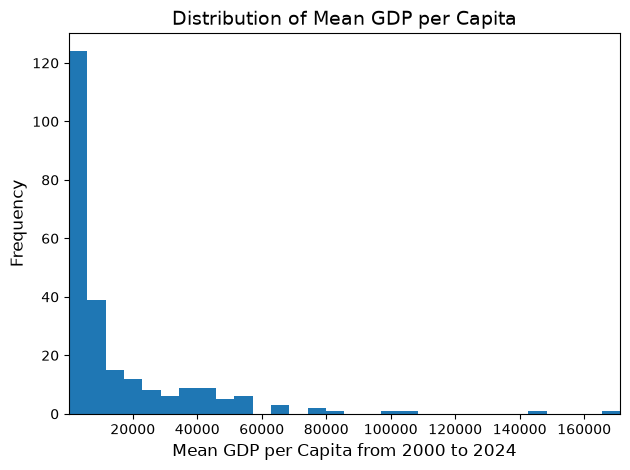

In [ ]:
plt.hist(
    data["GdpMean"],
    bins=30,
    range=(data["GdpMean"].min(), data["GdpMean"].max()),
)
plt.xlim(data["GdpMean"].min(), data["GdpMean"].max())
plt.xlabel("Mean GDP per Capita from 2000 to 2024", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Mean GDP per Capita", fontsize=14)

plt.tight_layout()
plt.show()

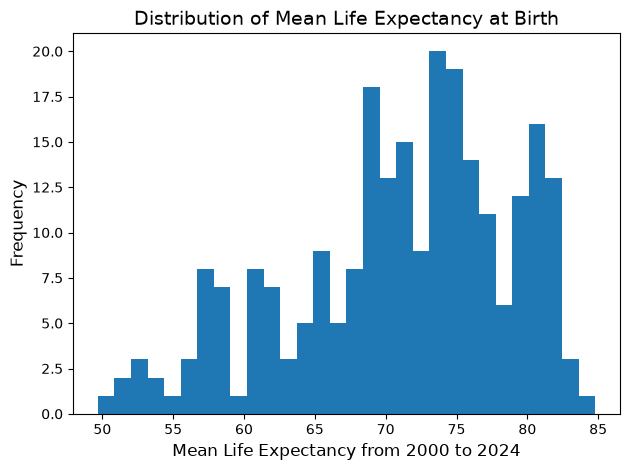

In [45]:
plt.hist(
    data["LifeExpectancyMean"],
    bins=30,
)

plt.xlabel("Mean Life Expectancy from 2000 to 2024", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Mean Life Expectancy at Birth", fontsize=14)

plt.tight_layout()
plt.show()

In [49]:
print(data["UnemploymentMean"].max())

32.92413043478261


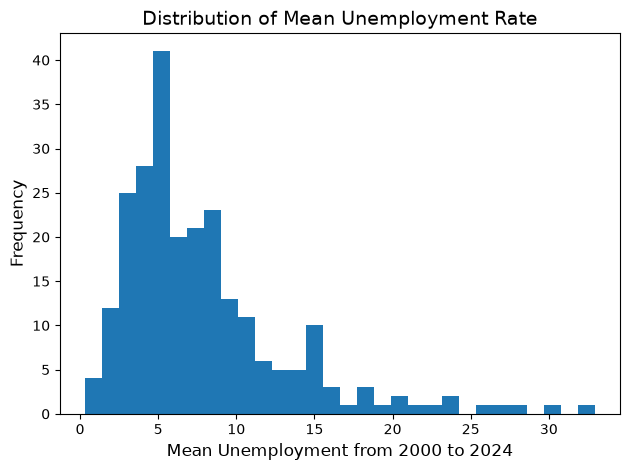

In [46]:
plt.hist(
    data["UnemploymentMean"],
    bins=30,
)

plt.xlabel("Mean Unemployment from 2000 to 2024", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Mean Unemployment Rate", fontsize=14)

plt.tight_layout()
plt.show()

In [13]:
for country in data["country_name"]:
    print(country)

Afghanistan
Africa Western and Central
Albania
Algeria
American Samoa
Angola
Antigua and Barbuda
Arab World
Argentina
Armenia
Aruba
Australia
Austria
Azerbaijan
Bahamas, The
Bahrain
Bangladesh
Barbados
Belarus
Belgium
Belize
Benin
Bermuda
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
Brunei Darussalam
Bulgaria
Burkina Faso
Burundi
Cabo Verde
Cambodia
Cameroon
Canada
Caribbean small states
Cayman Islands
Central Europe and the Baltics
Chad
Chile
China
Colombia
Comoros
Congo, Dem. Rep.
Congo, Rep.
Costa Rica
Cote d'Ivoire
Croatia
Cuba
Curacao
Cyprus
Czechia
Denmark
Djibouti
Dominica
Dominican Republic
Early-demographic dividend
East Asia & Pacific
East Asia & Pacific (IDA & IBRD countries)
East Asia & Pacific (excluding high income)
Ecuador
Egypt, Arab Rep.
El Salvador
Equatorial Guinea
Estonia
Eswatini
Ethiopia
Euro area
Europe & Central Asia
Europe & Central Asia (IDA & IBRD countries)
Europe & Central Asia (excluding high income)
European Union
Faroe Islands
Fiji
Finland
Franc

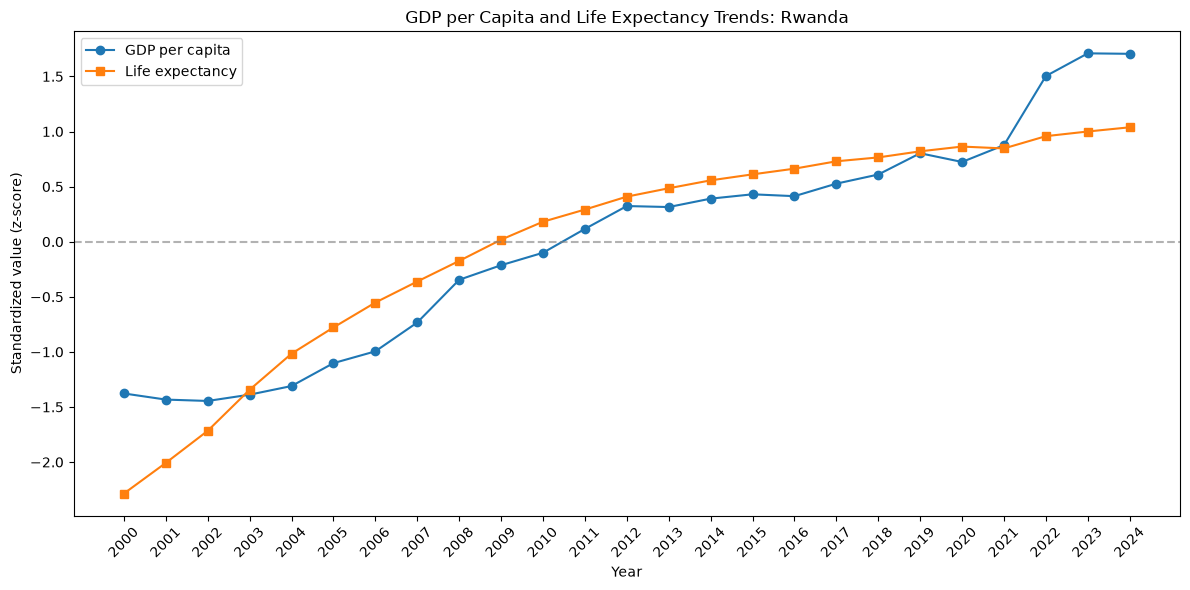

In [14]:
# Question 5: Within each country, how do changes in GDP per capita relate to changes in life expectancy?
# Get the data
gdp = df[df["series_name"] == "GDP per capita (current US$)"].set_index("country_name")[
    years
]


lifeExp = df[df["series_name"] == "Life expectancy at birth, total (years)"].set_index(
    "country_name"
)[years]

country = "Rwanda"

# Select country
gdp_country = gdp.loc[country]
life_country = lifeExp.loc[country]

# Standardize within country (z-scores)
gdp_z = (gdp_country - gdp_country.mean()) / gdp_country.std()
life_z = (life_country - life_country.mean()) / life_country.std()

# Plot
plt.figure(figsize=(12, 6))

plt.plot(years, gdp_z, marker="o", label="GDP per capita")
plt.plot(years, life_z, marker="s", label="Life expectancy")

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)

plt.title(f"GDP per Capita and Life Expectancy Trends: {country}")
plt.xlabel("Year")
plt.ylabel("Standardized value (z-score)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Bonus: Within each country, how do changes in GDP per capita relate to changes in life expectancy?
# Get the data
UnEmpRate = df[df["series_name"] == ""].set_index(
    "country_name"
)[years]

country = "Rwanda"

# Select country
gdp_country = gdp.loc[country]
life_country = lifeExp.loc[country]

# Standardize within country (z-scores)
gdp_z = (gdp_country - gdp_country.mean()) / gdp_country.std()
life_z = (life_country - life_country.mean()) / life_country.std()

# Plot
plt.figure(figsize=(12, 6))

plt.plot(years, gdp_z, marker="o", label="GDP per capita")
plt.plot(years, life_z, marker="s", label="Life expectancy")

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)

plt.title(f"GDP per Capita and Life Expectancy Trends: {country}")
plt.xlabel("Year")
plt.ylabel("Standardized value (z-score)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

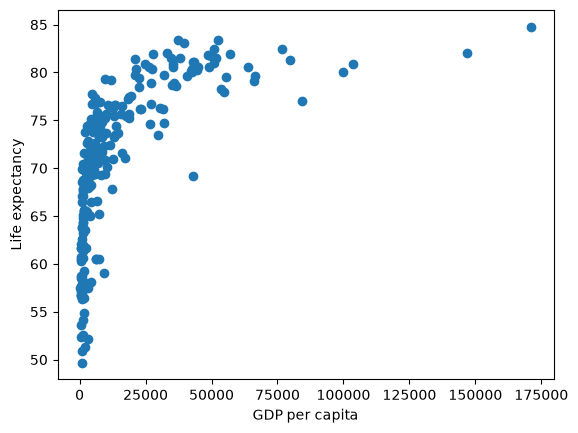

In [15]:
plt.scatter(data["GdpMean"], data["LifeExpectancyMean"])

plt.xlabel("GDP per capita")
plt.ylabel("Life expectancy")
plt.show()

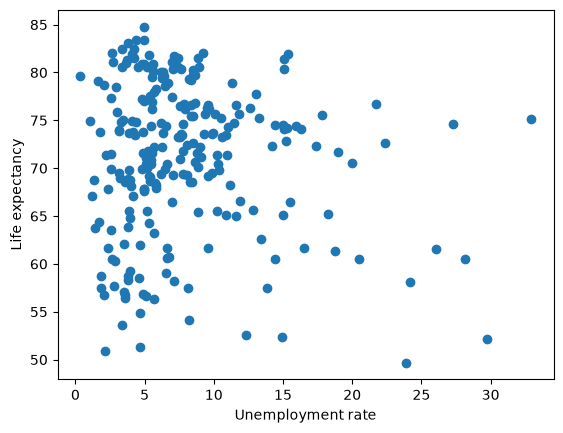

In [16]:
# Question 6: How is unemployment related to life expectancy?
plt.scatter(data["UnemploymentMean"], data["LifeExpectancyMean"])

plt.xlabel("Unemployment rate")
plt.ylabel("Life expectancy")
plt.show()

In [17]:
# Question 7: Which countries have high GDP per capita but also high unemployment?
high_gdp = data["GdpMean"] > data["GdpMean"].median()

high_uet = data["UnemploymentMean"] > data["UnemploymentMean"].median()

countries_gdp_uet = data[high_gdp & high_uet].drop(columns="LifeExpectancyMean")

for country in countries_gdp_uet["country_name"]:
    print(country)

American Samoa
Antigua and Barbuda
Argentina
Aruba
Bahamas, The
Barbados
Belgium
Botswana
Brazil
Bulgaria
Canada
Caribbean small states
Central Europe and the Baltics
Chile
Costa Rica
Croatia
Curacao
Cyprus
Dominica
Equatorial Guinea
Estonia
Euro area
Europe & Central Asia
Europe & Central Asia (IDA & IBRD countries)
European Union
Finland
France
French Polynesia
Gabon
Greece
Greenland
Grenada
Guam
Guyana
Hungary
Ireland
Israel
Italy
Kazakhstan
Latin America & Caribbean
Latin America & Caribbean (excluding high income)
Latin America & the Caribbean (IDA & IBRD countries)
Latvia
Lebanon
Libya
Lithuania
Mauritius
Montenegro
Naoero
New Caledonia
Northern Mariana Islands
OECD members
Other small states
Panama
Poland
Portugal
Puerto Rico (US)
Serbia
Slovak Republic
South Africa
Spain
St. Lucia
St. Vincent and the Grenadines
Sweden
Turkiye
Turks and Caicos Islands
Uruguay
Venezuela, RB


In [18]:
# Question 8: Which countries have low GDP per capita but relatively high life expectancy?
low_gdp = ~high_gdp

high_leb = data["LifeExpectancyMean"] > data["LifeExpectancyMean"].median()

countries_gdp_leb = data[low_gdp & high_leb].drop(columns="UnemploymentMean")

for country in countries_gdp_leb["country_name"]:
    print(country)

Albania
Algeria
Armenia
Bosnia and Herzegovina
Cabo Verde
Colombia
East Asia & Pacific (IDA & IBRD countries)
East Asia & Pacific (excluding high income)
Ecuador
Georgia
Iran, Islamic Rep.
Jordan
Kosovo
North Macedonia
Peru
Sri Lanka
Thailand
Tunisia
Viet Nam
West Bank and Gaza


In [30]:
for country in data[low_gdp]["country_name"]:
    gdp = data.loc[data["country_name"] == country, "GdpMean"].iloc[0]
    print(f"{country}: {round(gdp, 2)}")

print(
    f"\n\nCountries with a gdp lower than the median are: {data[low_gdp]["country_name"].count()}"
)

Afghanistan: 415.55
Africa Western and Central: 1534.61
Albania: 4663.28
Algeria: 4272.81
Angola: 2999.99
Arab World: 5607.41
Armenia: 3461.72
Azerbaijan: 4547.35
Bangladesh: 1229.91
Belarus: 5440.44
Belize: 5802.75
Benin: 1001.58
Bhutan: 2463.3
Bolivia: 2534.85
Bosnia and Herzegovina: 4748.41
Burkina Faso: 629.91
Burundi: 205.95
Cabo Verde: 3327.99
Cambodia: 1293.25
Cameroon: 1377.5
Chad: 875.57
Colombia: 5558.16
Comoros: 1341.88
Congo, Dem. Rep.: 401.54
Congo, Rep.: 2308.45
Cote d'Ivoire: 1709.53
Djibouti: 1839.42
Early-demographic dividend: 2824.58
East Asia & Pacific (IDA & IBRD countries): 5297.16
East Asia & Pacific (excluding high income): 5237.65
Ecuador: 4722.35
Egypt, Arab Rep.: 2431.95
El Salvador: 3454.26
Eswatini: 3259.92
Ethiopia: 495.74
Europe & Central Asia (excluding high income): 5520.66
Fiji: 4256.99
Gambia, The: 669.26
Georgia: 3767.05
Ghana: 1460.31
Guatemala: 3388.59
Guinea: 812.27
Guinea-Bissau: 644.73
Haiti: 1232.54
Honduras: 2022.1
IBRD only: 4747.52
IDA & IBRD

In [31]:
for country in data[high_gdp]["country_name"]:
    gdp = data.loc[data["country_name"] == country, "GdpMean"].iloc[0]
    print(f"{country}: {round(gdp, 2)}")

print(
    f"\n\nCountries with a gdp higher than the median are: {data[high_gdp]["country_name"].count()}"
)

American Samoa: 11575.38
Antigua and Barbuda: 16214.34
Argentina: 9813.06
Aruba: 26494.58
Australia: 48711.03
Austria: 44917.92
Bahamas, The: 29739.94
Bahrain: 22649.98
Barbados: 18540.6
Belgium: 42523.04
Bermuda: 99675.38
Botswana: 6086.36
Brazil: 8222.68
Brunei Darussalam: 31843.45
Bulgaria: 7733.69
Canada: 43387.98
Caribbean small states: 12562.05
Cayman Islands: 84137.95
Central Europe and the Baltics: 13002.01
Chile: 11841.52
China: 6413.35
Costa Rica: 9472.78
Croatia: 13523.44
Cuba: 5820.07
Curacao: 18646.34
Cyprus: 27558.44
Czechia: 19325.82
Denmark: 55595.07
Dominica: 7535.12
Dominican Republic: 6036.53
East Asia & Pacific: 8567.04
Equatorial Guinea: 9194.37
Estonia: 17569.39
Euro area: 35438.39
Europe & Central Asia: 22919.79
Europe & Central Asia (IDA & IBRD countries): 7769.73
European Union: 32001.43
Faroe Islands: 50901.08
Finland: 44413.77
France: 38079.24
French Polynesia: 21059.93
Gabon: 7262.08
Germany: 42435.36
Greece: 21241.78
Greenland: 42886.95
Grenada: 7842.08
Gua